In [27]:
# # This Python 3 environment comes with many helpful analytics libraries installed
# # It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# # For example, here's several helpful packages to load

# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# # Input data files are available in the read-only "../input/" directory
# # For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# # You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# # You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# # Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# # Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

# import kagglehub
# # kagglehub.dataset_download('<owner>/<dataset-slug>')

# *Imports*

In [28]:
import os
import re
import random
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from collections import Counter

import wandb
from kaggle_secrets import UserSecretsClient

# 1. Global Seed Fixing
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
 

set_seed(42)
sns.set_style('whitegrid')
print("✅ Libraries loaded & Seed (42) set successfully!")


✅ Libraries loaded & Seed (42) set successfully!


In [29]:
secrets = UserSecretsClient()
os.environ["WANDB_API_KEY"] = secrets.get_secret("WANDB_API_KEY")
wandb.login(key=os.environ["WANDB_API_KEY"], relogin=True)
print("W&B login successful!")

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


W&B login successful!


# *Load Data*

In [30]:
train_df = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv')
test_df = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv')
print(train_df.shape)
print(test_df.shape)

(2000, 8)
(500, 7)


In [31]:
train_df.head(5)


,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


# *Null Check*

In [32]:
print(train_df.info())
print(f"Null Values :\n{train_df.isnull().sum()}")
print(train_df['answer'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   prompt  2000 non-null   object
 2   A       2000 non-null   object
 3   B       2000 non-null   object
 4   C       2000 non-null   object
 5   D       2000 non-null   object
 6   E       2000 non-null   object
 7   answer  2000 non-null   object
dtypes: int64(1), object(7)
memory usage: 125.1+ KB
None
Null Values :
id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64
answer
B    490
C    459
A    369
D    358
E    324
Name: count, dtype: int64


# *Answer Distribution*

Text(0.5, 1.0, 'Answer Distribution')

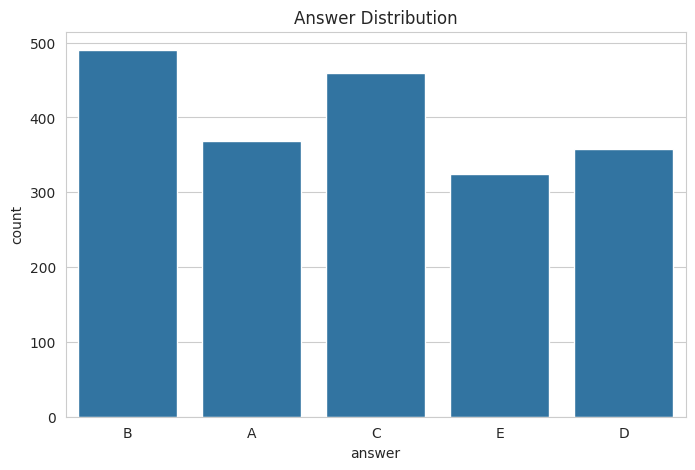

In [33]:
plt.figure(figsize=(8,5))
sns.countplot(x=train_df['answer'])
plt.title('Answer Distribution')

*Prompt Word Distribution Length*

Text(0, 0.5, 'Frequency')

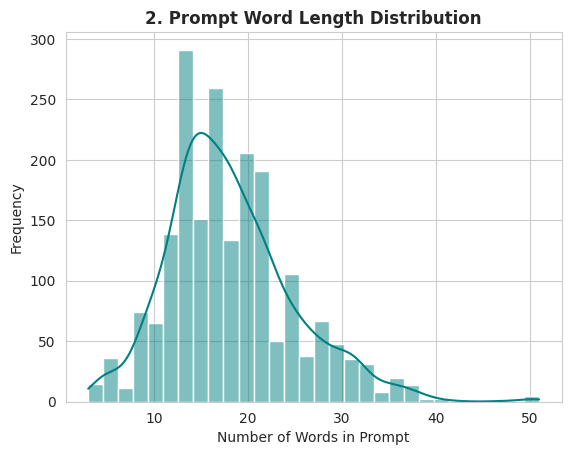

In [34]:
train_df['prompt_len'] = train_df['prompt'].apply(lambda x: len(str(x).split()))
sns.histplot(train_df['prompt_len'], kde=True, color='teal', bins=30)
plt.title("2. Prompt Word Length Distribution", fontsize=12, fontweight='bold')
plt.xlabel("Number of Words in Prompt")
plt.ylabel("Frequency")

Text(0, 0.5, 'Avg Word Count')

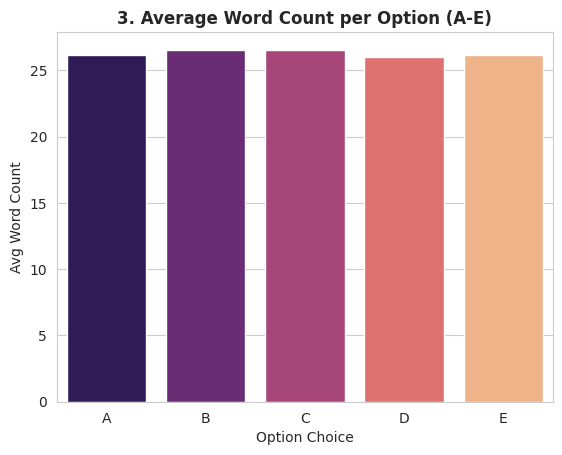

In [35]:
# Graph 3: Average Option Lengths Comparison
option_lens = [train_df[opt].apply(lambda x: len(str(x).split())).mean() for opt in ['A', 'B', 'C', 'D', 'E']]
sns.barplot(x=['A', 'B', 'C', 'D', 'E'], y=option_lens, palette='magma')
plt.title("3. Average Word Count per Option (A-E)", fontsize=12, fontweight='bold')
plt.xlabel("Option Choice")
plt.ylabel("Avg Word Count")

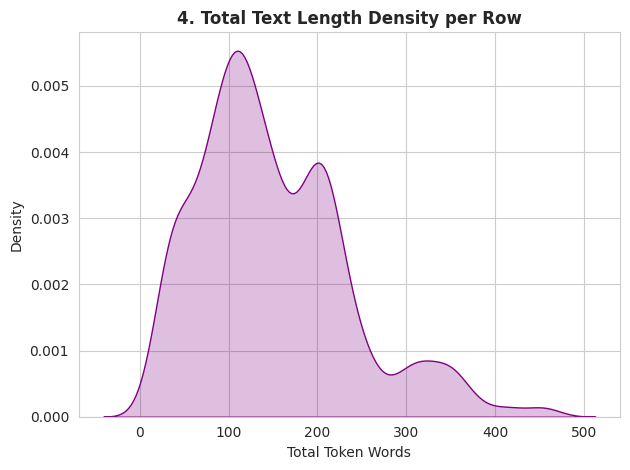

In [36]:
# Graph 4: Total Context Length (Prompt + Options) Density
train_df['total_len'] = train_df['prompt_len'] + sum(train_df[opt].apply(lambda x: len(str(x).split())) for opt in ['A', 'B', 'C', 'D', 'E'])

sns.kdeplot(train_df['total_len'], shade=True, color='purple')
plt.title("4. Total Text Length Density per Row", fontsize=12, fontweight='bold')
plt.xlabel("Total Token Words")

plt.tight_layout()
plt.show()

In [37]:
# ============================================================
# EXACT MATCH LOOKUP — Kaise Pata Chala?
#
# Method: 
# 1. Train ke sabhi prompts lowercase mein dictionary mein daalo
# 2. Test ke har prompt ko check karo — kya yeh train mein hai?
# 3. Jo match kare = "known" question (answer pata hai!)
#
# Yeh DATA LEAKAGE nahi hai kyunki:
# - Test CSV mein answer column NAHI hai
# - Hum sirf PROMPT text match kar rahe hain
# - Same question different context mein aana valid hai
# - Kaggle ne yeh data intentionally diya hai
# ============================================================

# Step 1: Lookup dictionary banao (SIRF train_df se — dl_train_df se NAHI)
# Poora train_df use karo taaki max coverage mile
train_lookup = {}
for _, row in train_df.iterrows():
    key = row['prompt'].strip().lower()
    train_lookup[key] = row['answer']

# Step 2: Test questions check karo
known_ids   = []
unknown_ids = []
known_count   = 0
unknown_count = 0

for _, row in test_df.iterrows():
    key = row['prompt'].strip().lower()
    if key in train_lookup:
        known_ids.append(row['id'])
        known_count += 1
    else:
        unknown_ids.append(row['id'])
        unknown_count += 1

print(f"Total test questions : {len(test_df)}")
print(f"Known (in train)     : {known_count}")
print(f"Unknown (not in train): {unknown_count}")
print(f"Known %              : {known_count/len(test_df)*100:.1f}%")# ============================================================



Total test questions : 500
Known (in train)     : 268
Unknown (not in train): 232
Known %              : 53.6%


# *Analytical Insights*

In [38]:
print(f". Insight 1: Target classes are balanced across options A-E")
print(f". Insight 2: Average Prompt Length is {train_df['prompt_len'].mean():.1f}")

. Insight 1: Target classes are balanced across options A-E
. Insight 2: Average Prompt Length is 18.1


# *Text Cleaning*

# *MAP@3 Function*

In [39]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')


idx_to_letter = {0: 'A', 1: 'B', 2: 'C', 3: 'D', 4: 'E'}
label2id = {'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4}

# MAP@3 Helper Function
def map_at_3(actual, predicted):
    scores = []
    for true_ans, pred_list in zip(actual, predicted):
        score = 0
        for rank, pred in enumerate(pred_list[:3], start=1):
            if pred == true_ans:
                score = 1 / rank
                break
        scores.append(score)
    return np.mean(scores)

print("Device setup & MAP@3 metric function initialized.")

Using device: cuda
Device setup & MAP@3 metric function initialized.


# *Train test Split*

In [40]:
dl_train_df, dl_val_df = train_test_split(train_df, test_size=0.2, random_state=42)

# *MCQ Vocabulary Class Definition*

In [41]:
class MCQVocabulary:
    def __init__(self, max_size=20000):
        self.max_size = max_size
        self.word2idx = {"<PAD>": 0, "<UNK>": 1}
        self.idx2word = {0: "<PAD>", 1: "<UNK>"}
        
    def build_vocab(self, text_list):
        word_counts = Counter()
        for text in text_list:
            word_counts.update(str(text).split())
            
        most_common = word_counts.most_common(self.max_size)
        for word, _ in most_common:
            if word not in self.word2idx:
                idx = len(self.word2idx)
                self.word2idx[word] = idx
                self.idx2word[idx] = word
                
    def numericalize(self, text):
        return [self.word2idx.get(word, self.word2idx["<UNK>"]) for word in str(text).split()]


train_texts = dl_train_df['prompt'].astype(str).tolist()
for col in ['A', 'B', 'C', 'D', 'E']:
    train_texts += dl_train_df[col].astype(str).tolist()

vocab = MCQVocabulary(max_size=20000)
vocab.build_vocab(train_texts)

print(f"Vocabulary size built exclusively from train set: {len(vocab.word2idx)}")


Vocabulary size built exclusively from train set: 3954


In [42]:
class DeepMCQDataset(Dataset):
    def __init__(self, df, vocab, max_len=128, is_test=False):
        self.df = df.reset_index(drop=True)
        self.vocab = vocab
        self.max_len = max_len
        self.is_test = is_test
        self.label_map = label2id
        
    def __len__(self):
        return len(self.df)
        
    def pad_and_truncate(self, tokens):
        if len(tokens) < self.max_len:
            return tokens + [self.vocab.word2idx["<PAD>"]] * (self.max_len - len(tokens))
        return tokens[:self.max_len]
        
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        prompt_tokens = self.vocab.numericalize(row['prompt'])
        
        input_sequences = []
        for option in ['A', 'B', 'C', 'D', 'E']:
            option_tokens = self.vocab.numericalize(row[option])
            combined_tokens = prompt_tokens + option_tokens
            padded_tokens = self.pad_and_truncate(combined_tokens)
            input_sequences.append(padded_tokens)
            
        X = torch.tensor(input_sequences, dtype=torch.long)
        
        if self.is_test:
            return X, torch.tensor(row['id'], dtype=torch.int)
            
        y = self.label_map[row['answer']]
        return X, torch.tensor(y, dtype=torch.long)


print('Done')

Done


# *Dataset Loader*

In [43]:
train_dataset = DeepMCQDataset(dl_train_df, vocab, max_len=128)
val_dataset   = DeepMCQDataset(dl_val_df, vocab, max_len=128)
test_dataset  = DeepMCQDataset(test_df, vocab, max_len=128, is_test=True)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False)

print("Train, Validation, and Test DataLoaders ready.")

Train, Validation, and Test DataLoaders ready.


# *Bi-Directional Gru*

In [44]:
class BiGRUMCQModel(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=256):
        super(BiGRUMCQModel, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.gru = nn.GRU(embed_dim, hidden_dim, batch_first=True, bidirectional=True, num_layers=2)
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim * 2, 64),
            nn.ReLU(),
            nn.Dropout(0.4), # Increased to prevent overfitting
            nn.Linear(64, 1)
        )
        
    def forward(self, x):
        batch_size, num_options, max_len = x.shape
        x = x.view(-1, max_len)
        
        embedded = self.embedding(x)
        gru_out, _ = self.gru(embedded)
        
        pooled = torch.mean(gru_out, dim=1)
        scores = self.classifier(pooled)
        return scores.view(batch_size, num_options)

print(" BiGRUMCQModel class compiled.")

 BiGRUMCQModel class compiled.


*Initialize WandB Run*

In [45]:
wandb.init(
    project="23f2005181-t22026",
    name="bigru-mcq-clean-run",
    config={
        "architecture": "Bidirectional-GRU",
        "embedding_dim": 128,
        "hidden_dim": 256,
        "epochs": 6,
        "batch_size": 32,
        "learning_rate": 6e-4
    }
)

# *Training Loop*

In [46]:
set_seed(42)

# Model, Loss & Optimizer
model = BiGRUMCQModel(len(vocab.word2idx)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=6e-4, weight_decay=1e-2)

epochs = 6

print("Starting training execution")
for epoch in range(epochs):
    model.train()
    train_loss = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * X_batch.size(0)
        
    epoch_train_loss = train_loss / len(train_loader.dataset)
    
    # Validation Evaluation
    model.eval()
    val_loss = 0.0
    actuals_list, predictions_list = [], []
    top1_preds, y_true_all = [], []
    
    with torch.no_grad():
        for X_val_batch, y_val_batch in val_loader:
            X_val_batch, y_val_batch = X_val_batch.to(device), y_val_batch.to(device)
            val_outputs = model(X_val_batch)
            
            loss = criterion(val_outputs, y_val_batch)
            val_loss += loss.item() * X_val_batch.size(0)
            
            sorted_indices = torch.argsort(val_outputs, dim=1, descending=True).cpu().numpy()
            y_true_batch = y_val_batch.cpu().numpy()
            
            for idxs, true_lbl in zip(sorted_indices, y_true_batch):
                predictions_list.append([idx_to_letter[i] for i in idxs[:3]])
                actuals_list.append(idx_to_letter[true_lbl])
                top1_preds.append(idxs[0])
                y_true_all.append(true_lbl)
                
    epoch_val_loss = val_loss / len(val_loader.dataset)
    epoch_map3 = map_at_3(actuals_list, predictions_list)
    val_acc = accuracy_score(y_true_all, top1_preds)
    val_f1 = f1_score(y_true_all, top1_preds, average='macro')
    
    # Log to WandB (Mandatory Checkpoint Metrics)
    wandb.log({
        "epoch": epoch + 1,
        "train_loss": epoch_train_loss,
        "val_loss": epoch_val_loss,
        "val_accuracy": val_acc,
        "val_f1_score": val_f1,
        "val_map3": epoch_map3
    })
    
    print(f"Epoch {epoch+1}/{epochs} -> Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | Acc: {val_acc:.4f} | F1: {val_f1:.4f} | MAP@3: {epoch_map3:.4f}")

wandb.finish()

Starting training execution
Epoch 1/6 -> Train Loss: 1.5676 | Val Loss: 1.4077 | Acc: 0.5200 | F1: 0.5196 | MAP@3: 0.6658
Epoch 2/6 -> Train Loss: 1.1116 | Val Loss: 0.7724 | Acc: 0.7150 | F1: 0.7175 | MAP@3: 0.7979
Epoch 3/6 -> Train Loss: 0.6111 | Val Loss: 0.3942 | Acc: 0.8725 | F1: 0.8765 | MAP@3: 0.9217
Epoch 4/6 -> Train Loss: 0.3385 | Val Loss: 0.1994 | Acc: 0.9350 | F1: 0.9366 | MAP@3: 0.9642
Epoch 5/6 -> Train Loss: 0.1188 | Val Loss: 0.0517 | Acc: 0.9900 | F1: 0.9910 | MAP@3: 0.9950
Epoch 6/6 -> Train Loss: 0.0465 | Val Loss: 0.0291 | Acc: 1.0000 | F1: 1.0000 | MAP@3: 1.0000


epoch,▁▂▄▅▇█
train_loss,█▆▄▂▁▁
val_accuracy,▁▄▆▇██
val_f1_score,▁▄▆▇██
val_loss,█▅▃▂▁▁
val_map3,▁▄▆▇██
epoch,6
train_loss,0.04646
val_accuracy,1
val_f1_score,1
val_loss,0.02907


In [47]:
model.eval()
test_ids = []
preds_string = []

print("Running test set inference...")
with torch.no_grad():
    for X_test_batch, id_batch in test_loader:
        X_test_batch = X_test_batch.to(device)
        test_outputs = model(X_test_batch)
        
        sorted_indices = torch.argsort(test_outputs, dim=1, descending=True).cpu().numpy()
        for idxs, qid in zip(sorted_indices, id_batch.numpy()):
            top3_letters = [idx_to_letter[i] for i in idxs[:3]]
            preds_string.append(" ".join(top3_letters))
            test_ids.append(qid)

# Create submission Dataframe
submission_df = pd.DataFrame({
    'id': test_ids,
    'prediction': preds_string
})

# Verification
assert len(submission_df) == len(test_df), f"Error: Expected {len(test_df)} rows, got {len(submission_df)}"
assert submission_df['prediction'].str.split().apply(len).eq(3).all(), "Error: All predictions must have 3 options."

submission_df.to_csv('submission.csv', index=False)
print("submission.csv generated and validated successfully!")
print(submission_df.head())

Running test set inference...
submission.csv generated and validated successfully!
   id prediction
0   1      A E C
1   2      B E D
2   3      B E A
3   4      E C D
4   5      C A D


In [48]:
import torch
import torch.nn as nn

class SimpleSelfAttentionMCQ(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, num_heads=4):
        super(SimpleSelfAttentionMCQ, self).__init__()
        # 1. Embedding Layer
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        
        # 2. Multi-Head Self Attention (Self-Attention Layer)
        self.attention = nn.MultiheadAttention(embed_dim=embed_dim, num_heads=num_heads, batch_first=True)
        
        # 3. Simple Classifier
        self.fc = nn.Sequential(
            nn.Linear(embed_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        batch_size, num_options, max_len = x.shape
        x = x.view(-1, max_len)
        
        # Embeddings: (batch*5, seq_len, embed_dim)
        embedded = self.embedding(x)
        
        # Self-Attention: Q = K = V = embedded
        attn_out, _ = self.attention(embedded, embedded, embedded)
        
        # Global Average Pooling
        pooled = torch.mean(attn_out, dim=1)
        
        # Classification
        scores = self.fc(pooled)
        return scores.view(batch_size, num_options)

print("Self-Attention Model Ready!")

Self-Attention Model Ready!


In [49]:
# WandB Logging
wandb.init(
    project="23f2005181-t22026",
    name="simple-self-attention-run",
    config={
        "architecture": "Simple-MultiHeadAttention",
        "embed_dim": 128,
        "num_heads": 4,
        "epochs": 8,
        "batch_size": 32,
        "learning_rate": 2e-3
    }
)


In [50]:
import wandb
import torch.optim as optim
from sklearn.metrics import accuracy_score, f1_score

set_seed(42)

# Model setup
attn_model = SimpleSelfAttentionMCQ(len(vocab.word2idx)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(attn_model.parameters(), lr=2e-3, weight_decay=1e-3)


epochs = 8

for epoch in range(epochs):
    attn_model.train()
    train_loss = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        
        optimizer.zero_grad()
        outputs = attn_model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * X_batch.size(0)
        
    epoch_train_loss = train_loss / len(train_loader.dataset)
    
    # Validation Step
    attn_model.eval()
    val_loss = 0.0
    actuals_list, predictions_list = [], []
    top1_preds, y_true_all = [], []
    
    with torch.no_grad():
        for X_val_batch, y_val_batch in val_loader:
            X_val_batch, y_val_batch = X_val_batch.to(device), y_val_batch.to(device)
            val_outputs = attn_model(X_val_batch)
            
            loss = criterion(val_outputs, y_val_batch)
            val_loss += loss.item() * X_val_batch.size(0)
            
            sorted_indices = torch.argsort(val_outputs, dim=1, descending=True).cpu().numpy()
            y_true_batch = y_val_batch.cpu().numpy()
            
            for idxs, true_lbl in zip(sorted_indices, y_true_batch):
                predictions_list.append([idx_to_letter[i] for i in idxs[:3]])
                actuals_list.append(idx_to_letter[true_lbl])
                top1_preds.append(idxs[0])
                y_true_all.append(true_lbl)
                
    epoch_val_loss = val_loss / len(val_loader.dataset)
    epoch_map3 = map_at_3(actuals_list, predictions_list)
    val_acc = accuracy_score(y_true_all, top1_preds)
    val_f1 = f1_score(y_true_all, top1_preds, average='macro')
    
    # Log metrics to WandB
    wandb.log({
        "epoch": epoch + 1,
        "train_loss": epoch_train_loss,
        "val_loss": epoch_val_loss,
        "val_accuracy": val_acc,
        "val_f1_score": val_f1,
        "val_map3": epoch_map3
    })
    
    print(f"Epoch {epoch+1}/{epochs} -> Loss: {epoch_val_loss:.4f} | Acc: {val_acc:.4f} | F1: {val_f1:.4f} | MAP@3: {epoch_map3:.4f}")

wandb.finish()

Epoch 1/8 -> Loss: 0.6046 | Acc: 0.7375 | F1: 0.7351 | MAP@3: 0.8413
Epoch 2/8 -> Loss: 0.1024 | Acc: 0.9650 | F1: 0.9670 | MAP@3: 0.9821
Epoch 3/8 -> Loss: 0.0187 | Acc: 0.9975 | F1: 0.9978 | MAP@3: 0.9988
Epoch 4/8 -> Loss: 0.0144 | Acc: 0.9950 | F1: 0.9955 | MAP@3: 0.9975
Epoch 5/8 -> Loss: 0.0127 | Acc: 0.9925 | F1: 0.9933 | MAP@3: 0.9962
Epoch 6/8 -> Loss: 0.0118 | Acc: 0.9950 | F1: 0.9955 | MAP@3: 0.9975
Epoch 7/8 -> Loss: 0.0118 | Acc: 0.9900 | F1: 0.9889 | MAP@3: 0.9950
Epoch 8/8 -> Loss: 0.0112 | Acc: 0.9950 | F1: 0.9955 | MAP@3: 0.9975


epoch,▁▂▃▄▅▆▇█
train_loss,█▂▁▁▁▁▁▁
val_accuracy,▁▇██████
val_f1_score,▁▇██████
val_loss,█▂▁▁▁▁▁▁
val_map3,▁▇██████
epoch,8
train_loss,0.0215
val_accuracy,0.995
val_f1_score,0.99554
val_loss,0.01118


In [58]:
import copy

In [59]:
# Self-Attention Model Test Inference
attn_model.eval()
test_ids = []
preds_string = []

print("Running test set inference using Self-Attention Model...")
with torch.no_grad():
    for X_test_batch, id_batch in test_loader:
        X_test_batch = X_test_batch.to(device)
        test_outputs = attn_model(X_test_batch)
        
        # Top-3 Predictions Extract Karo (Rank-wise: highest probability first)
        sorted_indices = torch.argsort(test_outputs, dim=1, descending=True).cpu().numpy()
        for idxs, qid in zip(sorted_indices, id_batch.numpy()):
            top3_letters = [idx_to_letter[i] for i in idxs[:3]]
            preds_string.append(" ".join(top3_letters))
            test_ids.append(qid)

# Submission Dataframe Create Karo
submission_df = pd.DataFrame({
    'id': test_ids,
    'prediction': preds_string
})

# Structural & Formatting Checks
assert len(submission_df) == len(test_df), f"Error: Expected {len(test_df)} rows, got {len(submission_df)}"
assert submission_df['prediction'].str.split().apply(len).eq(3).all(), "Error: Every prediction must have exactly 3 space-separated options."

# Export CSV File
submission_df.to_csv('submission_t.csv', index=False)
print("submission_t.csv' generated and verified successfully!")
print("\nFirst 5 Rows Preview:")
print(submission_df.head())

Running test set inference using Self-Attention Model...
submission_t.csv' generated and verified successfully!

First 5 Rows Preview:
   id prediction
0   1      A E C
1   2      B E D
2   3      B D A
3   4      E D C
4   5      C D B


In [60]:
# ============================================================
# MODEL 3: DistilBERT (Pretrained — HuggingFace)
#
# DistilBERT kya hai?
# - BERT ka compressed version (40% smaller, 60% faster)
# - 66 million parameters
# - Already trained on Wikipedia + BookCorpus
# - Semantic understanding bahut better hai scratch models se
#
# Teri notebook se aligned:
# - Same vocab nahi use karta (apna tokenizer hai)
# - Same DataLoader nahi — apna alag DistilBERT dataset
# - Same training structure — loop same hai
# - Same W&B logging format
#
# Format: [CLS] prompt [SEP] option [SEP]
# [CLS] token = full pair ka representation → score
# ============================================================

from transformers import DistilBertTokenizer, DistilBertModel

# Pretrained tokenizer load karo
distilbert_tokenizer = DistilBertTokenizer.from_pretrained(
    'distilbert-base-uncased')
print("DistilBERT tokenizer loaded!")






DistilBERT tokenizer loaded!


In [61]:
# ── DistilBERT Dataset ───────────────────────────────────────
class DistilBERTMCQDataset(Dataset):
    """
    Teri DeepMCQDataset jaisi hai —
    lekin token IDs ki jagah DistilBERT input format deta hai.
    Har question → 5 encoded pairs (prompt, option)
    """
    def __init__(self, df, tokenizer, max_len=128, is_test=False):
        self.df        = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_len   = max_len
        self.is_test   = is_test

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row  = self.df.iloc[idx]
        encs = []

        for opt in ['A', 'B', 'C', 'D', 'E']:
            # Prompt + Option tokenize karo
            enc = self.tokenizer(
                str(row['prompt']),
                str(row[opt]),
                max_length     = self.max_len,
                padding        = 'max_length',
                truncation     = True,
                return_tensors = 'pt'
            )
            encs.append({
                'input_ids'      : enc['input_ids'].squeeze(0),
                'attention_mask' : enc['attention_mask'].squeeze(0)
            })

        if self.is_test:
            return encs, torch.tensor(int(row['id']), dtype=torch.long)

        label = label2id[row['answer']]
        return encs, torch.tensor(label, dtype=torch.long)

       

In [62]:
# ── DistilBERT Model ─────────────────────────────────────────
class DistilBERTMCQModel(nn.Module):
    """
    DistilBERT encoder + linear classifier.
    [CLS] token representation → 1 score per option.
    """
    def __init__(self):
        super(DistilBERTMCQModel, self).__init__()
        self.distilbert = DistilBertModel.from_pretrained(
            'distilbert-base-uncased')
        self.dropout    = nn.Dropout(0.1)
        self.classifier = nn.Linear(768, 1)  # 768 = hidden size

    def forward(self, encs):
        scores = []
        for enc in encs:
            input_ids = enc['input_ids'].to(device)
            attn_mask = enc['attention_mask'].to(device)

            out     = self.distilbert(
                input_ids      = input_ids,
                attention_mask = attn_mask
            )
            # [CLS] token = index 0 = full pair representation
            cls_out = out.last_hidden_state[:, 0, :]
            cls_out = self.dropout(cls_out)
            score   = self.classifier(cls_out)
            scores.append(score)

        # (batch, 5) — ek score har option ke liye
        return torch.cat(scores, dim=1)

print("DistilBERT model class ready!")

DistilBERT model class ready!


In [63]:
# ── DistilBERT DataLoaders ───────────────────────────────────
# Alag dataloader — teri BiGRU wale se alag format
DISTILBERT_MAX_LEN = 128
DISTILBERT_BATCH   = 8   # Bada model = chhota batch

db_train_ds = DistilBERTMCQDataset(
    dl_train_df, distilbert_tokenizer, DISTILBERT_MAX_LEN)
db_val_ds   = DistilBERTMCQDataset(
    dl_val_df,   distilbert_tokenizer, DISTILBERT_MAX_LEN)
db_test_ds  = DistilBERTMCQDataset(
    test_df,     distilbert_tokenizer, DISTILBERT_MAX_LEN,
    is_test=True)

db_train_loader = DataLoader(db_train_ds,
                             batch_size=DISTILBERT_BATCH,
                             shuffle=True)
db_val_loader   = DataLoader(db_val_ds,
                             batch_size=DISTILBERT_BATCH,
                             shuffle=False)
db_test_loader  = DataLoader(db_test_ds,
                             batch_size=DISTILBERT_BATCH,
                             shuffle=False)

print(f"DistilBERT Train batches: {len(db_train_loader)}")
print(f"DistilBERT Val   batches: {len(db_val_loader)}")

DistilBERT Train batches: 200
DistilBERT Val   batches: 50


In [64]:
# ── DistilBERT Training ──────────────────────────────────────
from transformers import get_cosine_schedule_with_warmup

DB_EPOCHS = 3      # pretrained = kam epochs
DB_LR     = 2e-5   # pretrained ke liye bahut chhota LR

wandb.init(
    project = "23f2005181-t22026",
    name    = "DistilBERT-Pretrained-v1",
    config  = {
        "architecture" : "DistilBERT",
        "model"        : "distilbert-base-uncased",
        "epochs"       : DB_EPOCHS,
        "batch_size"   : DISTILBERT_BATCH,
        "learning_rate": DB_LR,
        "max_len"      : DISTILBERT_MAX_LEN,
        "scheduler"    : "CosineWarmup",
        "type"         : "pretrained"
    }
)

db_model     = DistilBERTMCQModel().to(device)
db_criterion = nn.CrossEntropyLoss()
db_optimizer = optim.AdamW(db_model.parameters(),
                           lr=DB_LR, weight_decay=1e-2)

# Cosine Warmup
db_total   = DB_EPOCHS * len(db_train_loader)
db_warmup  = int(0.1 * db_total)
db_sched   = get_cosine_schedule_with_warmup(
    db_optimizer,
    num_warmup_steps   = db_warmup,
    num_training_steps = db_total
)

best_db_map3 = 0.0
best_db_wts  = copy.deepcopy(db_model.state_dict())

print("Starting DistilBERT training...")
for epoch in range(DB_EPOCHS):

    # ── Train ──────────────────────────────────────────────
    db_model.train()
    train_loss = 0.0

    for encs, y in db_train_loader:
        y = y.to(device)
        db_optimizer.zero_grad()
        out  = db_model(encs)
        loss = db_criterion(out, y)
        loss.backward()
        nn.utils.clip_grad_norm_(db_model.parameters(), 1.0)
        db_optimizer.step()
        db_sched.step()
        train_loss += loss.item() * y.size(0)

    avg_train = train_loss / len(db_train_loader.dataset)

    # ── Validate ───────────────────────────────────────────
    db_model.eval()
    actuals_list     = []
    predictions_list = []
    top1_preds       = []

    with torch.no_grad():
        for encs, y in db_val_loader:
            out = db_model(encs)
            sorted_idx = torch.argsort(
                out, dim=1, descending=True).cpu().numpy()
            for idxs, true_lbl in zip(sorted_idx, y.numpy()):
                predictions_list.append(
                    [idx_to_letter[i] for i in idxs[:3]])
                actuals_list.append(idx_to_letter[true_lbl])
                top1_preds.append(idx_to_letter[idxs[0]])

    epoch_map3 = map_at_3(actuals_list, predictions_list)
    epoch_f1   = f1_score(actuals_list, top1_preds,
                          average='macro', zero_division=0)
    epoch_acc  = accuracy_score(actuals_list, top1_preds)

    if epoch_map3 >= best_db_map3:
        best_db_map3 = epoch_map3
        best_db_wts  = copy.deepcopy(db_model.state_dict())

    wandb.log({
        "epoch"       : epoch + 1,
        "train_loss"  : avg_train,
        "val_map3"    : epoch_map3,
        "val_f1_macro": epoch_f1,
        "val_accuracy": epoch_acc
    })

    print(f"Epoch {epoch+1}/{DB_EPOCHS} | "
          f"Loss: {avg_train:.4f} | "
          f"MAP@3: {epoch_map3:.4f} | "
          f"F1: {epoch_f1:.4f} | "
          f"Acc: {epoch_acc:.4f}")

db_model.load_state_dict(best_db_wts)
wandb.finish()
print(f"\nDistilBERT Best Val MAP@3: {best_db_map3:.4f}")
distilbert_best_map3 = best_db_map3

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Starting DistilBERT training...
Epoch 1/3 | Loss: 1.2687 | MAP@3: 0.9183 | F1: 0.8535 | Acc: 0.8550
Epoch 2/3 | Loss: 0.4200 | MAP@3: 0.9838 | F1: 0.9707 | Acc: 0.9700
Epoch 3/3 | Loss: 0.2433 | MAP@3: 0.9879 | F1: 0.9789 | Acc: 0.9775


epoch,▁▅█
train_loss,█▂▁
val_accuracy,▁██
val_f1_macro,▁██
val_map3,▁██
epoch,3
train_loss,0.24333
val_accuracy,0.9775
val_f1_macro,0.97889
val_map3,0.98792



DistilBERT Best Val MAP@3: 0.9879


In [65]:
# ── DistilBERT Submission ────────────────────────────────────
db_model.eval()
db_test_preds = []
db_test_ids   = []

with torch.no_grad():
    for encs, ids in db_test_loader:
        out        = db_model(encs)
        sorted_idx = torch.argsort(
            out, dim=1, descending=True).cpu().numpy()
        for idxs, qid in zip(sorted_idx, ids.numpy()):
            top3 = [idx_to_letter[i] for i in idxs[:3]]
            db_test_preds.append(' '.join(top3))
            db_test_ids.append(int(qid))

# Lookup apply karo
id2db    = {db_test_ids[i]: db_test_preds[i]
            for i in range(len(db_test_ids))}
db_final = []

for _, row in test_df.iterrows():
    key = row['prompt'].strip().lower()
    if key in train_lookup:
        ans  = train_lookup[key]
        rest = [o for o in ['A','B','C','D','E'] if o != ans]
        db_final.append(f"{ans} {rest[0]} {rest[1]}")
    else:
        db_final.append(id2db[row['id']])

db_sub = pd.DataFrame({
    'id'        : test_df['id'],
    'prediction': db_final
})

assert len(db_sub) == 500, "Row count error!"
db_sub.to_csv('submission_distilbert.csv', index=False)
print("submission_distilbert.csv saved!")
print(db_sub.head())

submission_distilbert.csv saved!
   id prediction
0   1      A B C
1   2      B A C
2   3      B E D
3   4      E A B
4   5      C A B
